## Identificação de grupos por concentração de crimes

### Objetivo

Foi identificado que a base combina duas populações muito diferentes: um pequeno conjunto de células H3 que concentra a maior parte dos crimes e uma cauda longa de células com volume baixo. O objetivo desta etapa é **identificar grupos de células com maior e menor concentração de crimes**, para avaliar e modelar cada população separadamente, com alvo, função de perda e features adequados ao seu comportamento, e medir em qual grupo os modelos de fato agregam valor em relação à média histórica.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [4]:
file = '../datasets/database_processed_h3.csv'

In [5]:
df_raw = pd.read_csv(file)

## 1. Conjunto de Treino
A clusterização será realizada exclusivamente sobre o conjunto de treino, evitando *data leakage*: o grupo de cada célula não deve depender de informações do período de teste.

In [6]:
df_raw['PERIODO'] = pd.to_datetime(dict(year=df_raw["ANO_BO"], month=df_raw["MES_BO"], day=1))

In [7]:
df_train = df_raw[(df_raw["PERIODO"] >= "2022-01-01") & (df_raw["PERIODO"] <= "2025-06-01")]

## 2. Distribuição de ocorrências de crimes por célula

In [8]:
vol = (df_train.groupby('H3')['CNT_CRIME']
                .sum()
                .sort_values(ascending=False)
                .rename('VOLUME')
                .to_frame())

In [9]:
vol['PCT_CRIMES'] = vol['VOLUME'] / vol['VOLUME'].sum()
vol['PCT_ACUM'] = vol['PCT_CRIMES'].cumsum()
vol['PCT_CELULAS'] = np.arange(1, len(vol) + 1) / len(vol)

In [11]:
print(vol['VOLUME'].describe(percentiles=[.1, .25, .5, .75, .9]))

count      1225.000000
mean       1693.045714
std        9830.997719
min           1.000000
10%           1.000000
25%           6.000000
50%          56.000000
75%        1172.000000
90%        4940.400000
max      323829.000000
Name: VOLUME, dtype: float64


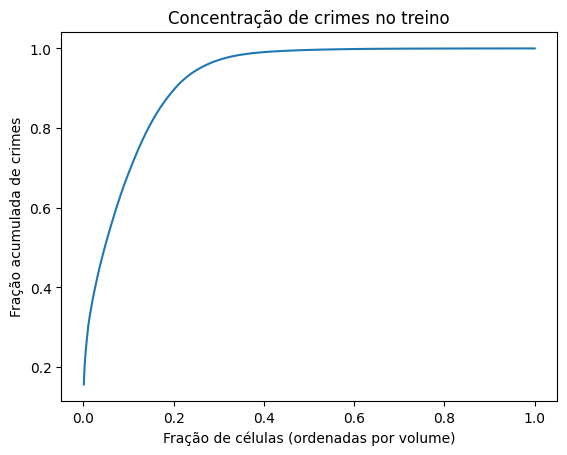

In [12]:
plt.plot(vol['PCT_CELULAS'], vol['PCT_ACUM'])
plt.xlabel('Fração de células (ordenadas por volume)')
plt.ylabel('Fração acumulada de crimes')
plt.title('Concentração de crimes no treino')
plt.show()

O corte de 80% dos crimes (princípio de Pareto) foi adotado como ponto de partida para definir o grupo de alto volume. Para verificar a sensibilidade da análise a essa escolha, os resultados foram comparados com cortes de 70% e 90%.

In [13]:
cortes = [0.70, 0.80, 0.90]

In [23]:
vol_s = vol['VOLUME'].sort_values(ascending=False)

In [24]:
meses_treino = pd.date_range(df_train['PERIODO'].min(), df_train['PERIODO'].max(), freq='MS')
grade = pd.MultiIndex.from_product([vol_s.index, meses_treino], names=['H3', 'PERIODO'])

In [25]:
cel_mes = (df_train.groupby(['H3', 'PERIODO'])['CNT_CRIME'].sum()
                    .reindex(grade, fill_value=0)
                    .reset_index())

In [26]:
por_cel = cel_mes.groupby('H3')['CNT_CRIME'].agg(media='mean', var='var')
por_cel['pct_meses_com_crime'] = cel_mes.assign(o=cel_mes['CNT_CRIME'] > 0).groupby('H3')['o'].mean() * 100
por_cel['dispersao'] = por_cel['var'] / por_cel['media']

In [27]:
def segmentar(vol, corte):
    acum = vol.cumsum() / vol.sum()
    seg = pd.Series(np.where(acum.shift(fill_value=0) < corte, 'alto', 'baixo'), index=vol.index)
    return seg

In [28]:
linhas = []
for c in cortes:
    seg = segmentar(vol_s, c).rename('segmento')
    r = por_cel.join(seg).groupby('segmento').agg(
        celulas=('media', 'size'),
        media_mes_mediana=('media', 'median'),
        pct_meses_com_crime_mediana=('pct_meses_com_crime', 'median'),
        dispersao_mediana=('dispersao', 'median'),
    )
    r.insert(0, 'corte', f'{int(c * 100)}%')
    linhas.append(r.reset_index())

In [29]:
print(pd.concat(linhas).round(2).to_string(index=False))

segmento corte  celulas  media_mes_mediana  pct_meses_com_crime_mediana  dispersao_mediana
    alto   70%      129             162.48                       100.00               3.49
   baixo   70%     1096               0.89                        57.14               1.16
    alto   80%      177             143.81                       100.00               3.18
   baixo   80%     1048               0.75                        50.00               1.14
    alto   90%      249             116.88                       100.00               2.80
   baixo   90%      976               0.57                        40.48               1.10
